
Training Set:
   Benign (0):       547  ( 53.8%)
   Malignant (1):    470  ( 46.2%)
   Total:           1017

Validation Set:
   Benign (0):       182  ( 53.7%)
   Malignant (1):    157  ( 46.3%)
   Total:            339

Test Set:
   Benign (0):       183  ( 53.8%)
   Malignant (1):    157  ( 46.2%)
   Total:            340

Combined Set:
   Benign (0):       912  ( 53.8%)
   Malignant (1):    784  ( 46.2%)
   Total:           1696
IMBALANCE ANALYSIS:
Benign:    912 (53.8%)
Malignant: 784 (46.2%)
Imbalance Ratio (Benign/Malignant): 1.16:1


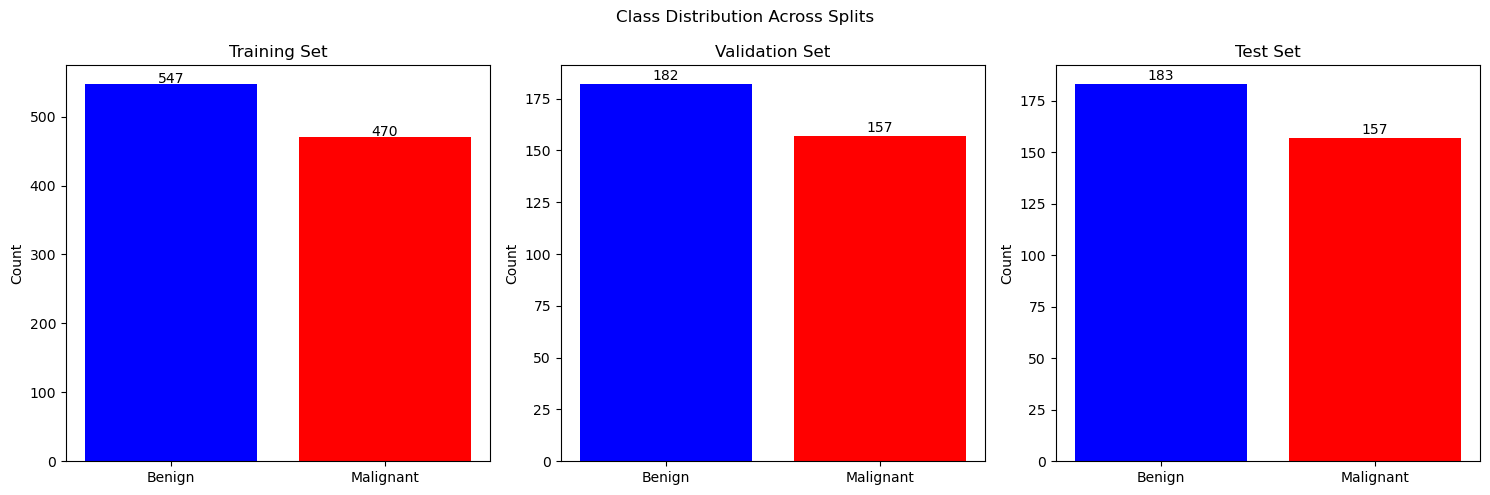

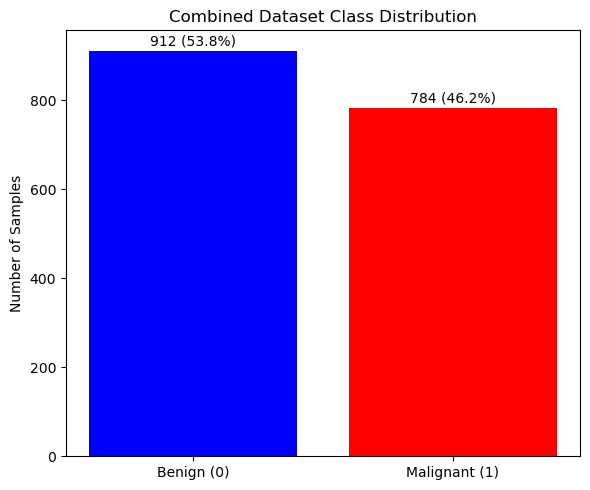


INTERPRETATION:
The dataset is imbalanced with 1.16x more benign than malignant cases.
The imbalance ratio is moderate. Class weights may still be beneficial.


In [2]:
# Notebook 2: Class Distribution
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Path to data
SAVE_DIR = "../processed_data/"

# Load data
X_train = np.load(os.path.join(SAVE_DIR, 'X_train.npy'))
y_train = np.load(os.path.join(SAVE_DIR, 'y_train.npy'))
X_val = np.load(os.path.join(SAVE_DIR, 'X_val.npy'))
y_val = np.load(os.path.join(SAVE_DIR, 'y_val.npy'))
X_test = np.load(os.path.join(SAVE_DIR, 'X_test.npy'))
y_test = np.load(os.path.join(SAVE_DIR, 'y_test.npy'))

# Combine all labels
y_all = np.concatenate([y_train, y_val, y_test])

# print distribution
def print_class_distribution(y, name):
    total = len(y)
    benign = np.sum(y == 0)
    malignant = np.sum(y == 1)
    print(f"\n{name}:")
    print(f"   Benign (0):    {benign:>6}  ({benign/total*100:>5.1f}%)")
    print(f"   Malignant (1): {malignant:>6}  ({malignant/total*100:>5.1f}%)")
    print(f"   Total:         {total:>6}")

print_class_distribution(y_train, "Training Set")
print_class_distribution(y_val, "Validation Set")
print_class_distribution(y_test, "Test Set")
print_class_distribution(y_all, "Combined Set")

# Imbalance ratio
benign_total = np.sum(y_all == 0)
malignant_total = np.sum(y_all == 1)
total = len(y_all)


print("IMBALANCE ANALYSIS:")
print(f"Benign:    {benign_total} ({benign_total/total*100:.1f}%)")
print(f"Malignant: {malignant_total} ({malignant_total/total*100:.1f}%)")
print(f"Imbalance Ratio (Benign/Malignant): {benign_total/malignant_total:.2f}:1")

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Individual splits
splits = ['Training', 'Validation', 'Test']
data = [y_train, y_val, y_test]
colors = ['#2ecc71', '#3498db', '#e74c3c']

for i, (split, y_data) in enumerate(zip(splits, data)):
    benign = np.sum(y_data == 0)
    malignant = np.sum(y_data == 1)
    axes[i].bar(['Benign', 'Malignant'], [benign, malignant], color=['blue', 'red'])
    axes[i].set_title(f'{split} Set')
    axes[i].set_ylabel('Count')
    # Add value labels
    axes[i].text(0, benign + 2, str(benign), ha='center')
    axes[i].text(1, malignant + 2, str(malignant), ha='center')

plt.suptitle('Class Distribution Across Splits')
plt.tight_layout()
plt.savefig('class_distribution_splits.png', dpi=150)
plt.show()

# Combined distribution
fig, ax = plt.subplots(figsize=(6, 5))
classes = ['Benign (0)', 'Malignant (1)']
counts = [benign_total, malignant_total]
bars = ax.bar(classes, counts, color=['blue', 'red'])
ax.set_title('Combined Dataset Class Distribution')
ax.set_ylabel('Number of Samples')
# Add value labels
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
            f'{count} ({count/total*100:.1f}%)', 
            ha='center', va='bottom')
plt.tight_layout()
plt.savefig('class_distribution_combined.png', dpi=150)
plt.show()

print("\nINTERPRETATION:")
print(f"The dataset is imbalanced with {benign_total/malignant_total:.2f}x more benign than malignant cases.")
if benign_total/malignant_total > 3:
    print("This is a significant imbalance. Consider using class weights or focal loss.")
else:
    print("The imbalance ratio is moderate. Class weights may still be beneficial.")